Tarea 3 – Procesamiento de Datos con Apache Spark

Tema: Análisis de datos para apoyar la gestión de inventarios mediante Apache Spark y Kafka.

Conjunto de datos: Online Retail, de UCI Machine Learning Repository.

Herramientas: Python, Apache Spark, DataFrames, RDD, Apache Kafka y Google Colab.

In [ ]:
%pip -q install pyspark==4.0.4 openpyxl pandas matplotlib kafka-python

import os
os.environ["PYSPARK_SUBMIT_ARGS"] = "--packages org.apache.spark:spark-sql-kafka-0-10_2.13:4.0.4 pyspark-shell"

print("Bibliotecas instaladas y configuración del conector preparada.")

Bibliotecas instaladas y configuración del conector preparada.


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("Tarea3_AnalisisVentas_Kafka")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "2")
    .getOrCreate()
)

print("Versión de Spark:", spark.version)
print("Sesión de Spark iniciada correctamente.")

Versión de Spark: 4.0.4
Sesión de Spark iniciada correctamente.


In [ ]:
import os
import pandas as pd

archivo = "/content/Online Retail.xlsx"

if not os.path.exists(archivo):
    from google.colab import files
    print("Sube el archivo Online Retail.xlsx descargado desde UCI.")
    cargados = files.upload()
    nombres = list(cargados.keys())
    if not nombres:
        raise FileNotFoundError("No se cargó ningún archivo.")
    archivo_subido = nombres[0]
    if not archivo_subido.lower().endswith(".xlsx"):
        raise ValueError("El archivo debe ser el Excel Online Retail.xlsx")
    os.rename(archivo_subido, archivo)

df = pd.read_excel(archivo)
print("Tamaño del conjunto de datos:", df.shape)
display(df.head())

Sube el archivo Online Retail.xlsx descargado desde UCI.


Saving Online Retail.xlsx to Online Retail.xlsx
Tamaño del conjunto de datos: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Convertir Excel a CSV y cargarlo en Spark
archivo_csv = "/content/online_retail.csv"
df.to_csv(archivo_csv, index=False)

datos_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(archivo_csv)
)

print("Total de registros:", datos_spark.count())
print("Total de columnas:", len(datos_spark.columns))
datos_spark.printSchema()
datos_spark.show(5, truncate=False)

Total de registros: 541909
Total de columnas: 8
root
 |-- InvoiceNo: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- CustomerID: double (nullable = true)
 |-- Country: string (nullable = true)

+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |
+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|536365   |85123A   |WHITE HANGING HEART T-LIGHT HOLDER |6       |2010-12-01 08:26:00|2.55     |17850.0   |United Kingdom|
|536365   |71053    |WHITE METAL LANTERN                |6       |2010-12-01 08:26:00|3.39     |17850.0   |United Kingdo

In [ ]:
print("=== REVISIÓN DE CALIDAD DE LOS DATOS ===")
datos_spark.select(
    F.sum(F.col("Description").isNull().cast("int")).alias("Descripcion_vacia"),
    F.sum(F.col("CustomerID").isNull().cast("int")).alias("Cliente_sin_ID"),
    F.sum(F.col("InvoiceNo").isNull().cast("int")).alias("Factura_vacia"),
    F.sum(F.col("StockCode").isNull().cast("int")).alias("Codigo_producto_vacio")
).show()

cancelaciones = datos_spark.filter(
    F.upper(F.trim(F.col("InvoiceNo").cast("string"))).startswith("C")
).count()
cantidades_invalidas = datos_spark.filter(F.col("Quantity") <= 0).count()
precios_invalidos = datos_spark.filter(F.col("UnitPrice") <= 0).count()
duplicados = datos_spark.count() - datos_spark.dropDuplicates().count()

print("Facturas con prefijo C:", cancelaciones)
print("Registros con cantidad menor o igual a cero:", cantidades_invalidas)
print("Registros con precio menor o igual a cero:", precios_invalidos)
print("Filas duplicadas exactas:", duplicados)

=== REVISIÓN DE CALIDAD DE LOS DATOS ===
+-----------------+--------------+-------------+---------------------+
|Descripcion_vacia|Cliente_sin_ID|Factura_vacia|Codigo_producto_vacio|
+-----------------+--------------+-------------+---------------------+
|             1454|        135080|            0|                    0|
+-----------------+--------------+-------------+---------------------+

Facturas con prefijo C: 9288
Registros con cantidad menor o igual a cero: 10624
Registros con precio menor o igual a cero: 2517
Filas duplicadas exactas: 5268


In [ ]:
ventas_limpias = datos_spark.dropDuplicates()

ventas_limpias = (
    ventas_limpias
    .withColumn("InvoiceNo", F.trim(F.col("InvoiceNo").cast("string")))
    .withColumn("StockCode", F.trim(F.col("StockCode").cast("string")))
    .withColumn("Description", F.trim(F.col("Description")))
    .withColumn("Quantity", F.col("Quantity").cast("integer"))
    .withColumn("UnitPrice", F.col("UnitPrice").cast("double"))
    .withColumn("InvoiceDate", F.to_timestamp("InvoiceDate"))
)

ventas_limpias = (
    ventas_limpias
    .filter(F.col("InvoiceNo").isNotNull())
    .filter(~F.upper(F.col("InvoiceNo")).startswith("C"))
    .filter(F.col("StockCode").isNotNull())
    .filter(F.col("Description").isNotNull())
    .filter(F.col("Description") != "")
    .filter(F.col("Quantity") > 0)
    .filter(F.col("UnitPrice") > 0)
    .withColumn("TotalVenta", F.round(F.col("Quantity") * F.col("UnitPrice"), 2))
    .withColumn("Fecha", F.to_date("InvoiceDate"))
    .withColumn("Mes", F.date_format("InvoiceDate", "yyyy-MM"))
)

originales = datos_spark.count()
limpios = ventas_limpias.count()
print("Registros originales:", originales)
print("Registros después de limpiar:", limpios)
print("Registros excluidos:", originales - limpios)
ventas_limpias.select(
    "InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "TotalVenta", "Mes"
).show(5, truncate=False)

Registros originales: 541909
Registros después de limpiar: 524878
Registros excluidos: 17031
+---------+---------+---------------------------------+--------+---------+----------+-------+
|InvoiceNo|StockCode|Description                      |Quantity|UnitPrice|TotalVenta|Mes    |
+---------+---------+---------------------------------+--------+---------+----------+-------+
|536365   |71053    |WHITE METAL LANTERN              |6       |3.39     |20.34     |2010-12|
|536365   |84029E   |RED WOOLLY HOTTIE WHITE HEART.   |6       |3.39     |20.34     |2010-12|
|536365   |22752    |SET 7 BABUSHKA NESTING BOXES     |2       |7.65     |15.3      |2010-12|
|536365   |21730    |GLASS STAR FROSTED T-LIGHT HOLDER|6       |4.25     |25.5      |2010-12|
|536366   |22632    |HAND WARMER RED POLKA DOT        |6       |1.85     |11.1      |2010-12|
+---------+---------+---------------------------------+--------+---------+----------+-------+
only showing top 5 rows


In [ ]:
top_productos = (
    ventas_limpias
    .groupBy("StockCode", "Description")
    .agg(
        F.sum("Quantity").alias("CantidadVendida"),
        F.round(F.sum("TotalVenta"), 2).alias("ValorVentas")
    )
    .orderBy(F.desc("CantidadVendida"))
)

top_productos.show(10, truncate=False)

+---------+----------------------------------+---------------+-----------+
|StockCode|Description                       |CantidadVendida|ValorVentas|
+---------+----------------------------------+---------------+-----------+
|23843    |PAPER CRAFT , LITTLE BIRDIE       |80995          |168469.6   |
|23166    |MEDIUM CERAMIC TOP STORAGE JAR    |78033          |81700.92   |
|84077    |WORLD WAR 2 GLIDERS ASSTD DESIGNS |54951          |13814.01   |
|85099B   |JUMBO BAG RED RETROSPOT           |48371          |94159.81   |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER|37580          |104284.24  |
|22197    |POPCORN HOLDER                    |36749          |34288.67   |
|21212    |PACK OF 72 RETROSPOT CAKE CASES   |36396          |21246.45   |
|84879    |ASSORTED COLOUR BIRD ORNAMENT     |36362          |58927.62   |
|23084    |RABBIT NIGHT LIGHT                |30739          |66870.03   |
|22492    |MINI PAINT SET VINTAGE            |26633          |16937.82   |
+---------+--------------

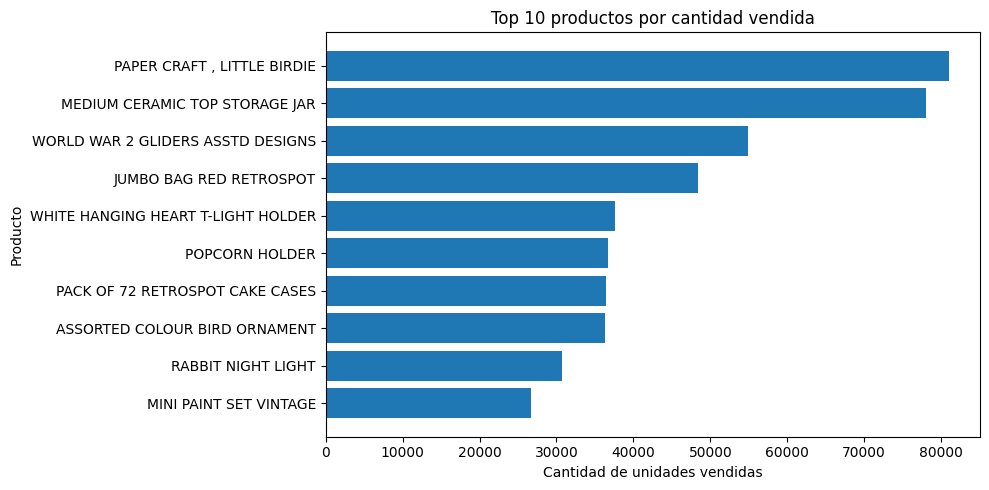

In [ ]:
import matplotlib.pyplot as plt

# Gráfica de los 10 productos con más unidades vendidas
grafico_productos = top_productos.limit(10).toPandas().sort_values(
    "CantidadVendida", ascending=True
)
plt.figure(figsize=(10, 5))
plt.barh(grafico_productos["Description"], grafico_productos["CantidadVendida"])
plt.title("Top 10 productos por cantidad vendida")
plt.xlabel("Cantidad de unidades vendidas")
plt.ylabel("Producto")
plt.tight_layout()
plt.savefig("/content/top_10_productos.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
ventas_mensuales = (
    ventas_limpias
    .groupBy("Mes")
    .agg(
        F.sum("Quantity").alias("UnidadesVendidas"),
        F.round(F.sum("TotalVenta"), 2).alias("ValorVentas")
    )
    .orderBy("Mes")
)
ventas_mensuales.show(20, truncate=False)

+-------+----------------+-----------+
|Mes    |UnidadesVendidas|ValorVentas|
+-------+----------------+-----------+
|2010-12|358019          |821452.73  |
|2011-01|387099          |689811.61  |
|2011-02|282934          |522545.56  |
|2011-03|376599          |716215.26  |
|2011-04|307953          |536968.49  |
|2011-05|395001          |769296.61  |
|2011-06|388511          |760547.01  |
|2011-07|399693          |718076.12  |
|2011-08|421020          |757841.38  |
|2011-09|569573          |1056435.19 |
|2011-10|621029          |1151263.73 |
|2011-11|751377          |1503866.78 |
|2011-12|313612          |637790.33  |
+-------+----------------+-----------+



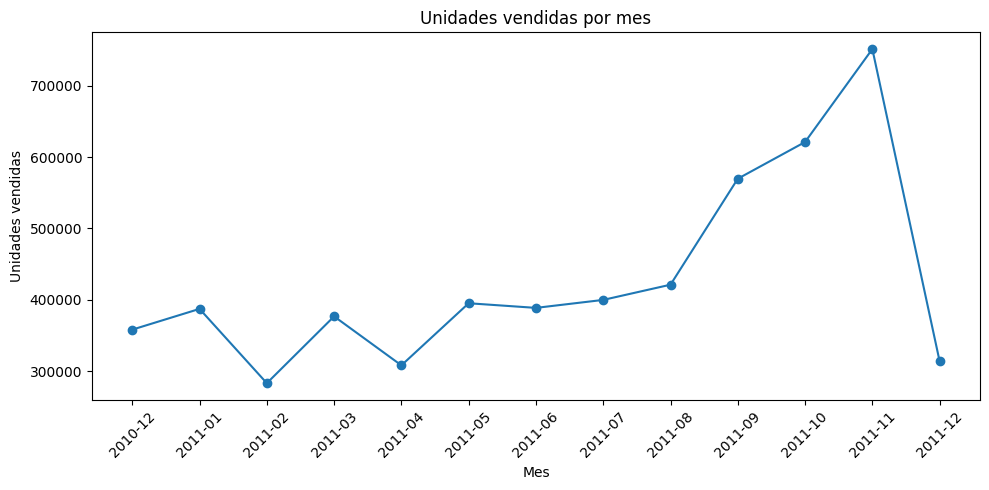

In [ ]:
grafico_mensual = ventas_mensuales.toPandas()
plt.figure(figsize=(10, 5))
plt.plot(grafico_mensual["Mes"], grafico_mensual["UnidadesVendidas"], marker="o")
plt.title("Unidades vendidas por mes")
plt.xlabel("Mes")
plt.ylabel("Unidades vendidas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("/content/ventas_mensuales.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Análisis equivalente con RDD: sumar unidades por código de producto
rdd_ventas = (
    ventas_limpias
    .select("StockCode", "Quantity")
    .rdd
    .map(lambda fila: (fila["StockCode"], fila["Quantity"]))
)
rdd_totales = rdd_ventas.reduceByKey(lambda cantidad1, cantidad2: cantidad1 + cantidad2)
top_rdd = rdd_totales.takeOrdered(10, key=lambda elemento: -elemento[1])

print("Top 10 productos mediante RDD:")
for codigo, cantidad in top_rdd:
    print(f"Producto: {codigo} | Unidades vendidas: {cantidad}")

Top 10 productos mediante RDD:
Producto: 23843 | Unidades vendidas: 80995
Producto: 23166 | Unidades vendidas: 78033
Producto: 22197 | Unidades vendidas: 56898
Producto: 84077 | Unidades vendidas: 54951
Producto: 85099B | Unidades vendidas: 48371
Producto: 85123A | Unidades vendidas: 37641
Producto: 21212 | Unidades vendidas: 36396
Producto: 84879 | Unidades vendidas: 36362
Producto: 23084 | Unidades vendidas: 30739
Producto: 22492 | Unidades vendidas: 26633


In [ ]:
# Opcional: descargar las gráficas del procesamiento por lotes
from google.colab import files
files.download("/content/ventas_mensuales.png")
files.download("/content/top_10_productos.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Comprobar que Java esté disponible
!java -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [ ]:
# Descargar y extraer Kafka 3.9.1 en el entorno actual de Colab
import os
KAFKA = "/content/kafka_2.13-3.9.1"

if not os.path.exists(f"{KAFKA}/bin/kafka-server-start.sh"):
    !wget -q https://archive.apache.org/dist/kafka/3.9.1/kafka_2.13-3.9.1.tgz -O /content/kafka.tgz
    !tar -xzf /content/kafka.tgz -C /content/

print("Kafka disponible:", os.path.exists(f"{KAFKA}/bin/kafka-server-start.sh"))

Kafka disponible: True


In [ ]:
# Formatear almacenamiento KRaft SOLO la primera vez en una sesión limpia.
# Si ya formateaste el almacenamiento en esta misma sesión, no vuelvas a ejecutar esta celda.
import subprocess

config_kafka = f"{KAFKA}/config/kraft/server.properties"
meta_dir = "/tmp/kraft-combined-logs/meta.properties"

if os.path.exists(meta_dir):
    print("El almacenamiento KRaft ya parece estar formateado; se omite este paso.")
else:
    resultado = subprocess.run(
        [f"{KAFKA}/bin/kafka-storage.sh", "random-uuid"],
        capture_output=True, text=True, check=True
    )
    CLUSTER_ID = resultado.stdout.strip()
    subprocess.run(
        [f"{KAFKA}/bin/kafka-storage.sh", "format", "-t", CLUSTER_ID, "-c", config_kafka],
        check=True
    )
    print("Almacenamiento KRaft formateado.")

Almacenamiento KRaft formateado.


In [ ]:
# Iniciar el servidor Kafka en segundo plano
import time

log_kafka = open("/content/kafka.log", "w")
proceso_kafka = subprocess.Popen(
    [f"{KAFKA}/bin/kafka-server-start.sh", config_kafka],
    stdout=log_kafka,
    stderr=subprocess.STDOUT,
    start_new_session=True
)
time.sleep(10)
if proceso_kafka.poll() is None:
    print("El proceso de Kafka sigue activo.")
else:
    print("Kafka no pudo iniciar. Últimas líneas del registro:")
    print(open("/content/kafka.log").read()[-3000:])

El proceso de Kafka sigue activo.


In [ ]:
# Crear el tema si todavía no existe
resultado_temas = subprocess.run(
    [f"{KAFKA}/bin/kafka-topics.sh", "--list", "--bootstrap-server", "localhost:9092"],
    capture_output=True, text=True
)
if "inventory-events" not in resultado_temas.stdout.splitlines():
    crear_tema = subprocess.run(
        [f"{KAFKA}/bin/kafka-topics.sh", "--create", "--topic", "inventory-events",
         "--bootstrap-server", "localhost:9092", "--partitions", "1", "--replication-factor", "1"],
        capture_output=True, text=True
    )
    print(crear_tema.stdout or crear_tema.stderr)
else:
    print("El tema inventory-events ya existe.")

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Created topic inventory-events.



In [ ]:
import json
from kafka import KafkaProducer

productor = KafkaProducer(
    bootstrap_servers="localhost:9092",
    value_serializer=lambda dato: json.dumps(dato).encode("utf-8")
)

ventas_simuladas = [
    {"StockCode": "23843", "Quantity": 3, "UnitPrice": 2.50},
    {"StockCode": "23166", "Quantity": 2, "UnitPrice": 8.50},
    {"StockCode": "22197", "Quantity": 5, "UnitPrice": 1.25},
    {"StockCode": "23843", "Quantity": 4, "UnitPrice": 2.50},
    {"StockCode": "85099B", "Quantity": 2, "UnitPrice": 1.95},
    {"StockCode": "23166", "Quantity": 6, "UnitPrice": 8.50},
    {"StockCode": "22197", "Quantity": 3, "UnitPrice": 1.25},
    {"StockCode": "23843", "Quantity": 1, "UnitPrice": 2.50}
]

for venta in ventas_simuladas:
    venta["timestamp"] = time.strftime("%Y-%m-%d %H:%M:%S")
    productor.send("inventory-events", value=venta)
    productor.flush()
    print("Evento enviado:", venta)
    time.sleep(1)
productor.close()
print("Envío de ocho eventos simulados finalizado.")

Evento enviado: {'StockCode': '23843', 'Quantity': 3, 'UnitPrice': 2.5, 'timestamp': '2026-10-28 15:54:45'}
Evento enviado: {'StockCode': '23166', 'Quantity': 2, 'UnitPrice': 8.5, 'timestamp': '2026-10-28 15:54:47'}
Evento enviado: {'StockCode': '22197', 'Quantity': 5, 'UnitPrice': 1.25, 'timestamp': '2026-10-28 15:54:48'}
Evento enviado: {'StockCode': '23843', 'Quantity': 4, 'UnitPrice': 2.5, 'timestamp': '2026-10-28 15:54:49'}
Evento enviado: {'StockCode': '85099B', 'Quantity': 2, 'UnitPrice': 1.95, 'timestamp': '2026-10-28 15:54:50'}
Evento enviado: {'StockCode': '23166', 'Quantity': 6, 'UnitPrice': 8.5, 'timestamp': '2026-10-28 15:54:51'}
Evento enviado: {'StockCode': '22197', 'Quantity': 3, 'UnitPrice': 1.25, 'timestamp': '2026-10-28 15:54:52'}
Evento enviado: {'StockCode': '23843', 'Quantity': 1, 'UnitPrice': 2.5, 'timestamp': '2026-10-28 15:54:53'}
Envío de ocho eventos simulados finalizado.


In [ ]:
from pyspark.sql.functions import col, from_json
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType

esquema_ventas = StructType([
    StructField("StockCode", StringType(), True),
    StructField("Quantity", IntegerType(), True),
    StructField("UnitPrice", DoubleType(), True),
    StructField("timestamp", StringType(), True)
])

eventos_kafka = (
    spark.readStream
    .format("kafka")
    .option("kafka.bootstrap.servers", "localhost:9092")
    .option("subscribe", "inventory-events")
    .option("startingOffsets", "earliest")
    .load()
)

ventas_tiempo_real = (
    eventos_kafka
    .selectExpr("CAST(value AS STRING) AS mensaje")
    .select(from_json(col("mensaje"), esquema_ventas).alias("venta"))
    .select("venta.*")
)

print("¿La fuente es de streaming?:", ventas_tiempo_real.isStreaming)
ventas_tiempo_real.printSchema()

¿La fuente es de streaming?: True
root
 |-- StockCode: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- timestamp: string (nullable = true)



In [ ]:
# Mostrar los mensajes recibidos. availableNow procesa los mensajes disponibles y luego termina.
consulta_ventas = (
    ventas_tiempo_real
    .select("StockCode", "Quantity", "UnitPrice", "timestamp")
    .writeStream
    .format("console")
    .outputMode("append")
    .option("truncate", "false")
    .trigger(availableNow=True)
    .start()
)
consulta_ventas.awaitTermination()
print("Procesamiento de los eventos disponibles finalizado.")
print("Progreso de la consulta:", consulta_ventas.lastProgress)

Procesamiento de los eventos disponibles finalizado.
Progreso de la consulta: {
    "id": "15e06d16-1b1d-426d-affb-b1dd1916a1e3",
    "runId": "16cdc57a-2bd0-4886-ba1e-a3b572431639",
    "name": null,
    "timestamp": "2026-10-28T15:56:45.282Z",
    "batchId": 0,
    "batchDuration": 3656,
    "numInputRows": 8,
    "inputRowsPerSecond": 0.0,
    "processedRowsPerSecond": 2.1881838074398248,
    "durationMs": {
        "addBatch": 1905,
        "commitOffsets": 337,
        "getBatch": 27,
        "latestOffset": 1133,
        "queryPlanning": 139,
        "triggerExecution": 3646,
        "walCommit": 73
    },
    "stateOperators": [],
    "sources": [
        {
            "description": "KafkaV2[Subscribe[inventory-events]]",
            "startOffset": null,
            "endOffset": {
                "inventory-events": {
                    "0": 8
                }
            },
            "latestOffset": {
                "inventory-events": {
                    "0": 8
       

In [ ]:
eventos_verificacion = (
    spark.read
    .format("kafka")
    .option("kafka.bootstrap.servers", "localhost:9092")
    .option("subscribe", "inventory-events")
    .option("startingOffsets", "earliest")
    .option("endingOffsets", "latest")
    .load()
)

ventas_verificacion = (
    eventos_verificacion
    .selectExpr("CAST(value AS STRING) AS mensaje")
    .select(from_json(col("mensaje"), esquema_ventas).alias("venta"))
    .select("venta.*")
)

resumen_eventos = ventas_verificacion.agg(
    F.sum("Quantity").alias("UnidadesProcesadas"),
    F.round(F.sum(col("Quantity") * col("UnitPrice")), 2).alias("ValorTotalSimulado")
)
resumen_eventos.show()

+------------------+------------------+
|UnidadesProcesadas|ValorTotalSimulado|
+------------------+------------------+
|                26|             101.9|
+------------------+------------------+



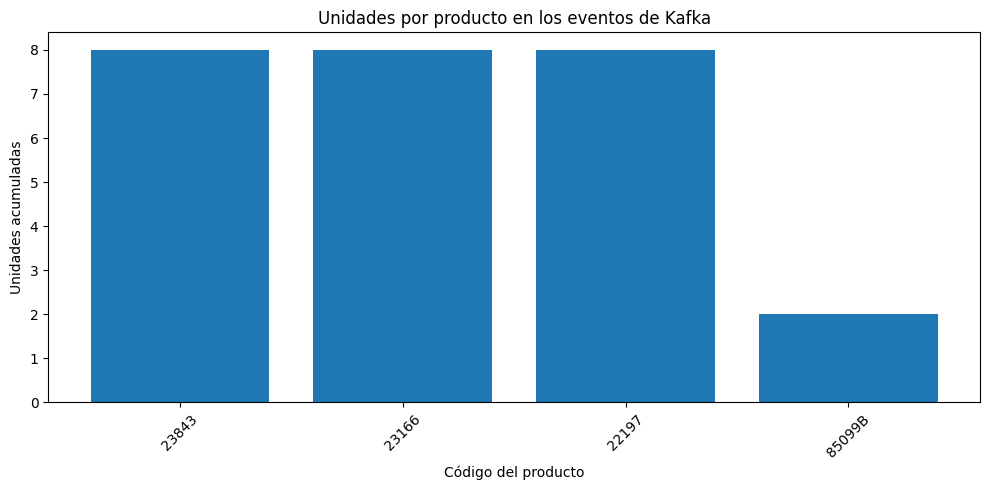

In [ ]:
# Gráfica de unidades acumuladas por código de producto
unidades_por_producto = (
    ventas_verificacion
    .groupBy("StockCode")
    .agg(F.sum("Quantity").alias("Unidades"))
    .orderBy(F.col("Unidades").desc())
)
datos_grafica = unidades_por_producto.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(datos_grafica["StockCode"].astype(str), datos_grafica["Unidades"])
plt.title("Unidades por producto en los eventos de Kafka")
plt.xlabel("Código del producto")
plt.ylabel("Unidades acumuladas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("/content/grafica_eventos_kafka.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Descargar la gráfica de Kafka
from google.colab import files
files.download("/content/grafica_eventos_kafka.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>